# 01 — EDA: база знаний R6 Siege и датасет токсичности

Модуль 1 пет-проекта **Player Support Copilot**.

1. Что собралось из Rainbow Six Wiki (Fandom, CC BY-SA 3.0): объём, длины, категории, что отсеяли фильтры и дедупликация, покрытие патчей.
2. Jigsaw Toxic Comment (CC BY-SA 3.0): дисбаланс классов и длины — задел на Модуль 4.

Запуск: `uv sync --group eda`, затем `uv run copilot ingest`, затем этот ноутбук.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from copilot.db.session import get_engine

pd.set_option('display.width', 120)
plt.rcParams['figure.figsize'] = (9, 4)

docs = pd.read_sql(text('''
    SELECT id, category, title, status, filter_reason, duplicate_of, lang,
           char_len, patch_version, text_md
    FROM documents'''), get_engine())
runs = pd.read_sql(text('SELECT * FROM ingest_runs ORDER BY id'), get_engine())
print(f'{len(docs)} documents, {len(runs)} ingest runs')

416 documents, 6 ingest runs


## 1. База знаний

### Объём по категориям и статусам

In [2]:
kept = docs[docs.status.isin(['new', 'changed', 'unchanged'])]
summary = docs.pivot_table(index='category', columns='status', values='id',
                           aggfunc='count', fill_value=0)
summary['kept_chars_k'] = kept.groupby('category').char_len.sum().div(1000).round(0)
summary

status,filtered,new,unchanged,kept_chars_k
category,,,,
gadget,0,17,10,167.0
guide,0,0,6,17.0
map,0,23,10,168.0
operator,1,100,10,1360.0
patch,5,98,10,727.0
playlist,0,1,10,45.0
weapon,0,105,10,722.0


In [3]:
print('Причины отсева:')
print(docs.filter_reason.value_counts(dropna=True).to_string())
dups = docs[docs.status == 'duplicate'].merge(
    docs[['id', 'title']], left_on='duplicate_of', right_on='id', suffixes=('', '_orig'))
print(f'\nНечёткие дубликаты (MinHash, Jaccard ≥ 0.85): {len(dups)}')
dups[['category', 'title', 'title_orig']].head(15)

Причины отсева:
filter_reason
too_short    6

Нечёткие дубликаты (MinHash, Jaccard ≥ 0.85): 0


,category,title,title_orig


### Распределение длин (символы Markdown после очистки)

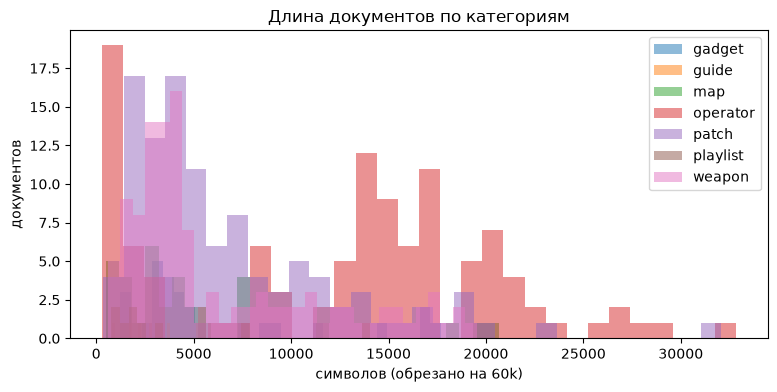

,count,mean,std,min,50%,90%,max
category,,,,,,,
gadget,27.0,6184.0,4987.0,1234.0,3992.0,15554.0,17689.0
guide,6.0,2754.0,1554.0,806.0,2477.0,4472.0,5243.0
map,33.0,5081.0,5240.0,512.0,3277.0,10718.0,20658.0
operator,110.0,12363.0,8039.0,290.0,13950.0,21168.0,32832.0
patch,108.0,6728.0,5540.0,369.0,4964.0,14281.0,32085.0
playlist,11.0,4092.0,3963.0,781.0,2348.0,7616.0,14075.0
weapon,115.0,6279.0,5064.0,603.0,3944.0,14958.0,19556.0


In [4]:
fig, ax = plt.subplots()
for cat, g in kept.groupby('category'):
    ax.hist(g.char_len.clip(upper=60_000), bins=30, alpha=0.5, label=cat)
ax.set_xlabel('символов (обрезано на 60k)'); ax.set_ylabel('документов'); ax.legend()
ax.set_title('Длина документов по категориям'); plt.show()
kept.groupby('category').char_len.describe(percentiles=[.5, .9]).round(0)

### Структура: сколько секций

Для чанкинга по структуре (этап 2) важно, что у документов есть заголовки.

In [5]:
kept = kept.assign(
    sections=kept.text_md.str.count(r'(?m)^#{2,4} '),
    words=kept.text_md.str.split().str.len(),
)
print(f"Документов без заголовков: {(kept.sections == 0).sum()} из {len(kept)}")
print(f"Всего слов: {kept.words.sum():,}  (~{kept.words.sum() * 1.3 / 1e6:.2f}M токенов)")
kept.groupby('category')[['sections', 'words']].median()

Документов без заголовков: 7 из 410
Всего слов: 558,765  (~0.73M токенов)


,sections,words
category,,
gadget,5.0,655.0
guide,2.0,451.0
map,7.0,555.0
operator,16.0,2291.5
patch,12.0,868.0
playlist,6.0,408.0
weapon,14.0,699.0


### Покрытие патчей

Версия патча нужна для фильтра актуальности в RAG.

Патчей: 108, с распознанной версией: 108


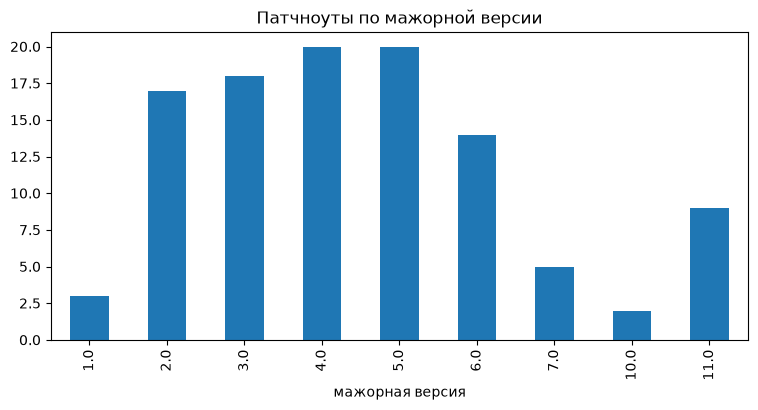

In [6]:
patches = kept[kept.category == 'patch'].copy()
patches['major'] = patches.patch_version.str.extract(r'^(\d+)').astype(float)
print(f"Патчей: {len(patches)}, с распознанной версией: {patches.patch_version.notna().sum()}")
ax = patches.major.value_counts().sort_index().plot.bar(title='Патчноуты по мажорной версии')
ax.set_xlabel('мажорная версия'); plt.show()

## 2. Jigsaw Toxic Comment

In [7]:
from pathlib import Path

JIGSAW_URL = ('https://huggingface.co/datasets/thesofakillers/'
              'jigsaw-toxic-comment-classification-challenge/resolve/main/train.csv')
cache = Path('../data/jigsaw_train.csv')  # data/ is git-ignored
if not cache.exists():
    cache.parent.mkdir(exist_ok=True)
    pd.read_csv(JIGSAW_URL).to_csv(cache, index=False)
jig = pd.read_csv(cache)
labels = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
jig['any_toxic'] = jig[labels].max(axis=1)
print(f'{len(jig):,} комментариев')
rates = (jig[labels + ['any_toxic']].mean() * 100).round(2).rename('% positive')
rates.to_frame()

159,571 комментариев


,% positive
toxic,9.58
severe_toxic,1.00
obscene,5.29
threat,0.30
insult,4.94
identity_hate,0.88
any_toxic,10.17


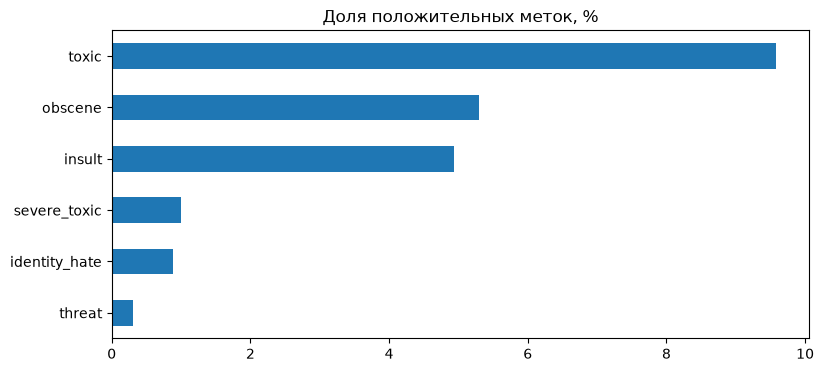

Дисбаланс ok:toxic ≈ 8.8:1 → нужны веса классов / F1 macro, не accuracy


In [8]:
ax = rates.drop('any_toxic').sort_values().plot.barh(title='Доля положительных меток, %')
plt.show()
imbalance = (1 - jig.any_toxic.mean()) / jig.any_toxic.mean()
print(f'Дисбаланс ok:toxic ≈ {imbalance:.1f}:1 → нужны веса классов / F1 macro, не accuracy')

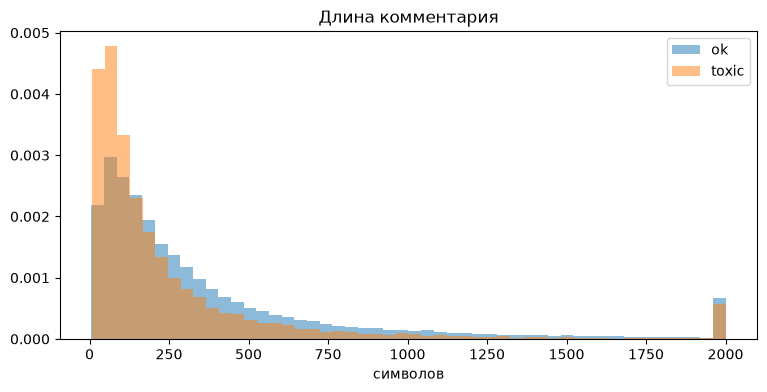

,count,mean,std,min,50%,95%,max
any_toxic,,,,,,,
0,143346.0,404.0,587.0,6.0,216.0,1386.0,5000.0
1,16225.0,303.0,619.0,8.0,128.0,1021.0,5000.0


In [9]:
jig['len'] = jig.comment_text.str.len()
fig, ax = plt.subplots()
for lab, g in jig.groupby('any_toxic'):
    ax.hist(g.len.clip(upper=2000), bins=50, alpha=0.5, density=True,
            label='toxic' if lab else 'ok')
ax.set_xlabel('символов'); ax.legend(); ax.set_title('Длина комментария'); plt.show()
jig.groupby('any_toxic').len.describe(percentiles=[.5, .95]).round(0)

### Игровой сленг

Риск для модерации: слова вроде *kill*, *destroy*, *noob* в игровом чате нормальны. Смотрим, как часто они встречаются в токсичных и нетоксичных комментариях Jigsaw (Wikipedia-обсуждения, не игровой чат).

In [10]:
slang = ['kill', 'shoot', 'dead', 'destroy', 'noob', 'trash', 'camp', 'rush', 'gg', 'ez']
rows = []
for w in slang:
    has = jig.comment_text.str.contains(rf'\b{w}\b', case=False, regex=True)
    rows.append({'word': w, 'comments': int(has.sum()),
                 'toxic_rate_%': round(jig.loc[has, 'any_toxic'].mean() * 100, 1)})
base = jig.any_toxic.mean() * 100
print(f'Базовая доля токсичных: {base:.1f}%')
pd.DataFrame(rows).sort_values('toxic_rate_%', ascending=False)

Базовая доля токсичных: 10.2%


,word,comments,toxic_rate_%
0,kill,540,47.2
4,noob,41,41.5
5,trash,144,39.6
1,shoot,167,31.1
3,destroy,308,23.7
8,gg,33,21.2
2,dead,902,17.3
7,rush,163,8.0
6,camp,163,5.5
9,ez,8,0.0


## Выводы

Цифры для README генерируются ячейкой ниже — после каждого нового ingest они пересчитываются.

In [11]:
n_patch = len(patches)
print(f"- База знаний: {len(kept)} документов, {kept.words.sum():,} слов; "
      f"отсеяно фильтрами {int((docs.status == 'filtered').sum())}, "
      f"дубликатов {int((docs.status == 'duplicate').sum())}.")
print(f"- Медианная длина {int(kept.char_len.median()):,} символов; "
      f"{(kept.sections > 0).mean():.0%} документов со структурой из заголовков.")
print(f"- Патчноутов {n_patch}, версия распознана у "
      f"{patches.patch_version.notna().mean():.0%}.")
print(f"- Jigsaw: {len(jig):,} комментариев, токсичных {jig.any_toxic.mean():.1%}, "
      f"threat всего {jig.threat.mean():.2%} → дисбаланс ≈ {imbalance:.0f}:1.")
risky = [r['word'] for r in rows if r['toxic_rate_%'] > 2 * base]
print(f"- Игровые слова с токсичностью выше базовой в 2+ раза: {', '.join(risky)} → "
      'риск ложных срабатываний модерации на игровом сленге (в RISKS.md).')

- База знаний: 410 документов, 558,765 слов; отсеяно фильтрами 6, дубликатов 0.
- Медианная длина 4,825 символов; 98% документов со структурой из заголовков.
- Патчноутов 108, версия распознана у 100%.
- Jigsaw: 159,571 комментариев, токсичных 10.2%, threat всего 0.30% → дисбаланс ≈ 9:1.
- Игровые слова с токсичностью выше базовой в 2+ раза: kill, shoot, destroy, noob, trash, gg → риск ложных срабатываний модерации на игровом сленге (в RISKS.md).
